In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt  
from sklearn.decomposition import PCA
import statsmodels.api as sm
import statsmodels.formula.api as smf
from yellowbrick.features import PCA as PcaViz

# abrimos el archivo usando una función específica de pandas
raw_dataset = pd.read_csv("CKD_NHANES_2021_2023.csv")

print(raw_dataset)

       participant_id   age  gender           ethnicity  education_level  \
0            130378.0  43.0    Male  Non-Hispanic Asian              5.0   
1            130379.0  66.0    Male  Non-Hispanic White              5.0   
2            130380.0  44.0  Female      Other Hispanic              3.0   
3            130381.0   5.0  Female   Other/Multiracial              NaN   
4            130382.0   2.0    Male  Non-Hispanic White              NaN   
...               ...   ...     ...                 ...              ...   
11928        142306.0   9.0    Male      Other Hispanic              NaN   
11929        142307.0  49.0  Female  Non-Hispanic Black              5.0   
11930        142308.0  50.0    Male      Other Hispanic              4.0   
11931        142309.0  40.0    Male      Other Hispanic              4.0   
11932        142310.0  80.0  Female  Non-Hispanic White              3.0   

       poverty_income_ratio   bmi  weight_kg  height_cm  bp_systolic  ...  \
0         

In [2]:
raw_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 11933 entries, 0 to 11932
Data columns (total 29 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   participant_id            11933 non-null  float64
 1   age                       11933 non-null  float64
 2   gender                    11933 non-null  str    
 3   ethnicity                 11933 non-null  str    
 4   education_level           7794 non-null   float64
 5   poverty_income_ratio      9892 non-null   float64
 6   bmi                       8471 non-null   float64
 7   weight_kg                 8754 non-null   float64
 8   height_cm                 8499 non-null   float64
 9   bp_systolic               7517 non-null   float64
 10  bp_diastolic              7517 non-null   float64
 11  serum_creatinine          6326 non-null   float64
 12  blood_urea_nitrogen       6326 non-null   float64
 13  albumin_serum             6366 non-null   float64
 14  phosphorus       

In [3]:
raw_dataset.head()

,participant_id,age,gender,ethnicity,education_level,poverty_income_ratio,bmi,weight_kg,height_cm,bp_systolic,...,urine_albumin,albumin_creatinine_ratio,diabetes_diagnosed,insulin_use,diabetes_pills,ever_smoked,current_smoker,egfr,ckd_stage,ckd_present
0,130378.0,43.0,Male,Non-Hispanic Asian,5.0,5.00,27.0,86.9,179.5,135.0,...,23.12,17.00,2.0,NaN,NaN,1.0,3.0,112.61,No CKD,0
1,130379.0,66.0,Male,Non-Hispanic White,5.0,5.00,33.5,101.8,174.2,121.0,...,4.25,6.64,2.0,NaN,NaN,1.0,3.0,97.98,No CKD,0
2,130380.0,44.0,Female,Other Hispanic,3.0,1.41,29.7,69.4,152.9,111.0,...,12.43,7.92,1.0,2.0,1.0,2.0,NaN,111.69,No CKD,0
3,130381.0,5.0,Female,Other/Multiracial,NaN,1.53,23.8,34.3,120.1,NaN,...,16.12,7.75,2.0,NaN,NaN,NaN,NaN,NaN,Unknown,1
4,130382.0,2.0,Male,Non-Hispanic White,NaN,3.60,NaN,13.6,NaN,NaN,...,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,Unknown,1


In [4]:
raw_dataset.describe()

,participant_id,age,education_level,poverty_income_ratio,bmi,weight_kg,height_cm,bp_systolic,bp_diastolic,serum_creatinine,...,urine_creatinine,urine_albumin,albumin_creatinine_ratio,diabetes_diagnosed,insulin_use,diabetes_pills,ever_smoked,current_smoker,egfr,ckd_present
count,11933.000000,1.193300e+04,7794.000000,9.892000e+03,8471.000000,8754.000000,8499.000000,7517.000000,7517.000000,6326.000000,...,8154.000000,8153.000000,8153.000000,11740.000000,1081.000000,2281.000000,8135.000000,3243.000000,6326.000000,11933.000000
mean,136344.000000,3.831786e+01,3.804978,2.708174e+00,27.246665,70.549037,159.664549,119.288546,72.748038,0.872828,...,133.258646,35.567928,33.355533,1.934497,1.681776,1.633494,1.611678,2.339500,96.599750,0.698986
std,3444.904716,2.560199e+01,1.153750,1.670119e+00,8.137781,30.389021,19.864943,18.561052,11.895572,0.385498,...,90.676053,175.582217,251.094041,0.358726,0.466002,0.635776,0.558182,0.900889,24.633731,0.458718
min,130378.000000,5.397605e-79,1.000000,5.397605e-79,11.100000,2.700000,79.100000,61.000000,33.000000,0.330000,...,4.000000,0.210000,0.080000,1.000000,1.000000,1.000000,1.000000,1.000000,3.510000,0.000000
25%,133361.000000,1.300000e+01,3.000000,1.180000e+00,21.600000,54.200000,154.400000,106.000000,64.000000,0.700000,...,65.000000,5.770000,5.420000,2.000000,1.000000,1.000000,1.000000,1.000000,80.502500,0.000000
50%,136344.000000,3.700000e+01,4.000000,2.500000e+00,26.400000,71.700000,163.600000,117.000000,72.000000,0.830000,...,117.000000,9.620000,8.270000,2.000000,2.000000,2.000000,2.000000,3.000000,97.030000,1.000000
75%,139327.000000,6.200000e+01,5.000000,4.500000e+00,31.700000,89.100000,172.100000,130.000000,80.000000,0.980000,...,181.000000,17.830000,15.330000,2.000000,2.000000,2.000000,2.000000,3.000000,112.660000,1.000000
max,142310.000000,8.000000e+01,9.000000,5.000000e+00,74.800000,248.200000,200.700000,232.000000,142.000000,15.170000,...,873.000000,7942.470000,14708.280000,9.000000,2.000000,9.000000,9.000000,3.000000,178.430000,1.000000


In [5]:

# 1. Define tu lista personalizable de valores nulos (¡modifícala a tu gusto!)
valores_nulos = ["unknown", "Unknown", "UNKNOWN", "n/a", "NA", "?", "","7","9",]

# 2. Reemplazamos esos valores por np.nan en una copia temporal
# Usamos regex=False para evitar problemas con caracteres especiales
raw_dataset_temp = raw_dataset.replace(valores_nulos, np.nan)

# 3. Calculamos el porcentaje de nulos por columna (variable)
porcentaje_nulos = (raw_dataset_temp.isnull().mean() * 100).round(2)

# 4. Mostramos el resultado ordenado de mayor a menor porcentaje
print(porcentaje_nulos.sort_values(ascending=False))

insulin_use                 90.94
diabetes_pills              80.88
current_smoker              72.82
phosphorus                  47.02
bicarbonate                 47.00
blood_urea_nitrogen         46.99
ckd_stage                   46.99
egfr                        46.99
serum_creatinine            46.99
uric_acid                   46.96
calcium                     46.69
albumin_serum               46.65
bp_systolic                 37.01
bp_diastolic                37.01
education_level             34.69
ever_smoked                 31.83
urine_albumin               31.68
albumin_creatinine_ratio    31.68
urine_creatinine            31.67
bmi                         29.01
height_cm                   28.78
weight_kg                   26.64
poverty_income_ratio        17.10
diabetes_diagnosed           1.62
ethnicity                    0.00
participant_id               0.00
age                          0.00
gender                       0.00
ckd_present                  0.00
dtype: float64

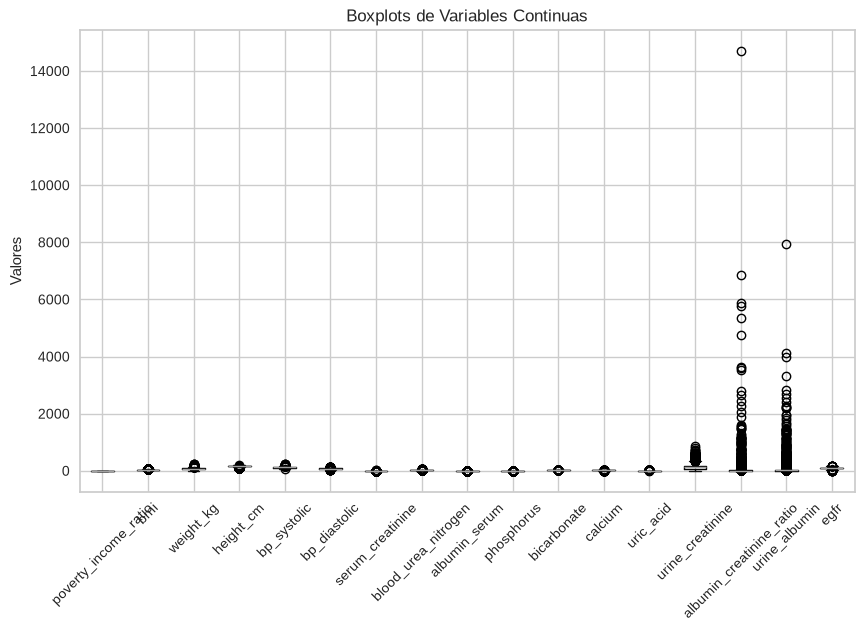

In [6]:

# Generar el boxplot agrupado para las variables seleccionadas

Cuantitativa_continua=["poverty_income_ratio","bmi","weight_kg","height_cm","bp_systolic","bp_diastolic","serum_creatinine","blood_urea_nitrogen","albumin_serum","phosphorus","bicarbonate","calcium","uric_acid","urine_creatinine","albumin_creatinine_ratio","urine_albumin","egfr"]

raw_dataset[Cuantitativa_continua].boxplot(figsize=(10, 6), rot=45)

plt.title('Boxplots de Variables Continuas')
plt.ylabel('Valores')
plt.grid(True)
plt.show()

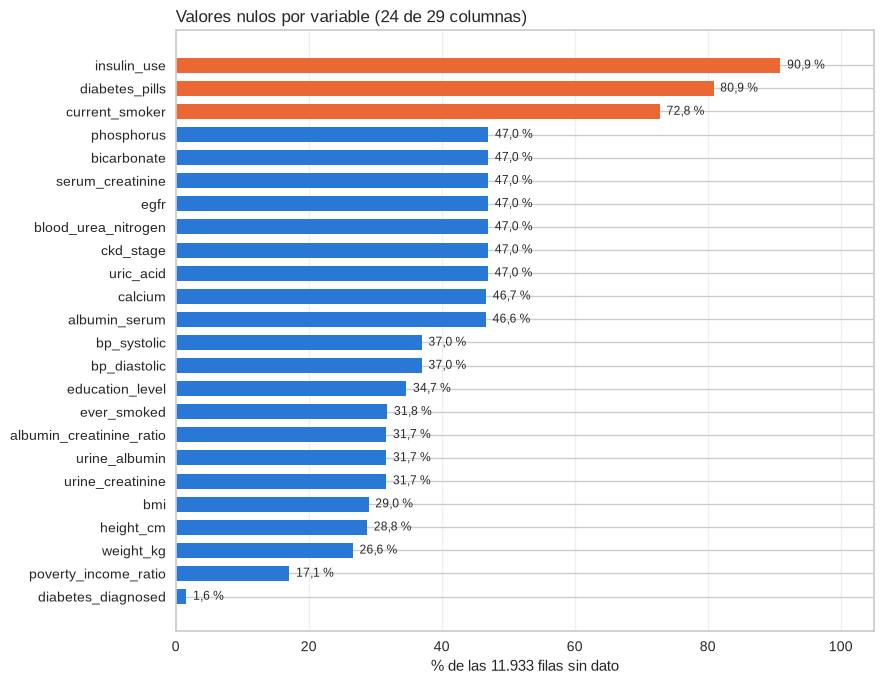

In [7]:


# 1-3. Mismo cálculo de tu celda
valores_nulos = ["unknown", "Unknown", "UNKNOWN", "n/a", "NA", "?", "", "7", "9"]
raw_dataset_temp = raw_dataset.replace(valores_nulos, np.nan)
porcentaje_nulos = (raw_dataset_temp.isnull().mean() * 100).round(2)

# 4. Ordenado de mayor a menor, solo las variables con algún nulo
nulos = porcentaje_nulos[porcentaje_nulos > 0].sort_values(ascending=False)

# Los 3 primeros de un color y el resto de otro
colores = ["#eb6834"] * 3 + ["#2a78d6"] * (len(nulos) - 3)

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(nulos.index[::-1], nulos.values[::-1], color=colores[::-1], height=0.65)   # [::-1]: la mayor queda arriba
for y, v in enumerate(nulos.values[::-1]):
    ax.text(v + 1, y, f"{v:.1f} %".replace(".", ","), va="center", fontsize=8.5)

ax.set_xlim(0, 105)
ax.set_xlabel(f"% de las {len(raw_dataset):,} filas sin dato".replace(",", "."))
ax.set_title(f"Valores nulos por variable ({len(nulos)} de {raw_dataset.shape[1]} columnas)", loc="left")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

In [8]:
#limpieza del dataset
Clean = raw_dataset

Cualitativa_Ordinal= ["education_level","insulin_use","ckd_stage"]
Cualitativa_Nominal= ["gender","ethnicity","diabetes_diagnosed","diabetes_pills","ever_smoked","current_smoker","ckd_present"]
Cuantitativa_discreta=["participant_id","age"]
Cuantitativa_continua=["poverty_income_ratio","bmi","weight_kg","height_cm","bp_systolic","bp_diastolic","serum_creatinine","blood_urea_nitrogen","albumin_serum","phosphorus","bicarbonate","calcium","uric_acid","urine_creatinine","albumin_creatinine_ratio","urine_albumin","egfr"]

#Comienzo por las Cuantitativas_continuas Rellenando por la media los valores nulos
for col in Cuantitativa_continua:
    Clean[col] = raw_dataset[col].fillna(raw_dataset[col].mean())

#En el caso de insulin_use, Tomo el por defecto de que Si no tenes diabetes. no tomas pastillas/insulina

Clean.loc[Clean['diabetes_diagnosed'] == 2.0, 'insulin_use'] = 2.0
Clean.loc[Clean['diabetes_diagnosed'] == 2.0, 'diabetes_pills'] = 2.0

#En el caso de Current_smoker, tomo en cuenta la pregunta de si Fumo alguna vez 

Clean.loc[(Clean['ever_smoked'] == 2.0) & (Clean['current_smoker'].isna()), 'current_smoker'] = 3.0

#A partir de ahi, consideramos que toda fila de la tabla que contenga un Not a number, se puede borrar para acomodar el dataset

Clean = Clean.dropna()

#Ahora nos deshacemos de los outliers 
for col in Cuantitativa_continua:
    limite_inferior = Clean[col].quantile(0.01)
    limite_superior = Clean[col].quantile(0.99)
    # Aplicar el recorte en la columna
    Clean[col] = Clean[col].clip(lower=limite_inferior, upper=limite_superior)

for col in Cuantitativa_discreta:
    limite_inferior = Clean[col].quantile(0.01)
    limite_superior = Clean[col].quantile(0.99)
    # Aplicar el recorte en la columna
    Clean[col] = Clean[col].clip(lower=limite_inferior, upper=limite_superior)


valores_nulos = ["unknown", "Unknownplt.show()", "UNKNOWN", "n/a", "NA", "?", "","7","9"]


# 2. Reemplazamos esos valores por np.nan en una copia temporal
# Usamos regex=False para evitar problemas con caracteres especiales
raw_dataset_temp = Clean.replace(valores_nulos, np.nan)

# 3. Calculamos el porcentaje de nulos por columna (variaClean)
porcentaje_nulos = (raw_dataset_temp.isnull().mean() * 100).round(2)

# 4. Mostramos el resultado ordenado de mayor a menor porcentaje
print(porcentaje_nulos.sort_values(ascending=False))
# Muestra todos los valores únicos y su frecuencia (incluyendo NaN)
#print(Clean[columna].value_counts(dropna=False))

participant_id              0.0
age                         0.0
gender                      0.0
ethnicity                   0.0
education_level             0.0
poverty_income_ratio        0.0
bmi                         0.0
weight_kg                   0.0
height_cm                   0.0
bp_systolic                 0.0
bp_diastolic                0.0
serum_creatinine            0.0
blood_urea_nitrogen         0.0
albumin_serum               0.0
phosphorus                  0.0
bicarbonate                 0.0
calcium                     0.0
uric_acid                   0.0
urine_creatinine            0.0
urine_albumin               0.0
albumin_creatinine_ratio    0.0
diabetes_diagnosed          0.0
insulin_use                 0.0
diabetes_pills              0.0
ever_smoked                 0.0
current_smoker              0.0
egfr                        0.0
ckd_stage                   0.0
ckd_present                 0.0
dtype: float64


In [9]:

# Muestra todos los valores únicos y su frecuencia (incluyendo NaN)
columna = 'ckd_stage'
print(raw_dataset[columna].value_counts(dropna=False))

ckd_stage
Unknown                         5607
No CKD                          3592
Stage 2 (Mildly Decreased)      1875
Stage 1 (Kidney Damage)          382
Stage 3a (Mild-Moderate)         341
Stage 3b (Moderate-Severe)        97
Stage 4 (Severely Decreased)      28
Stage 5 (Kidney Failure)          11
Name: count, dtype: int64


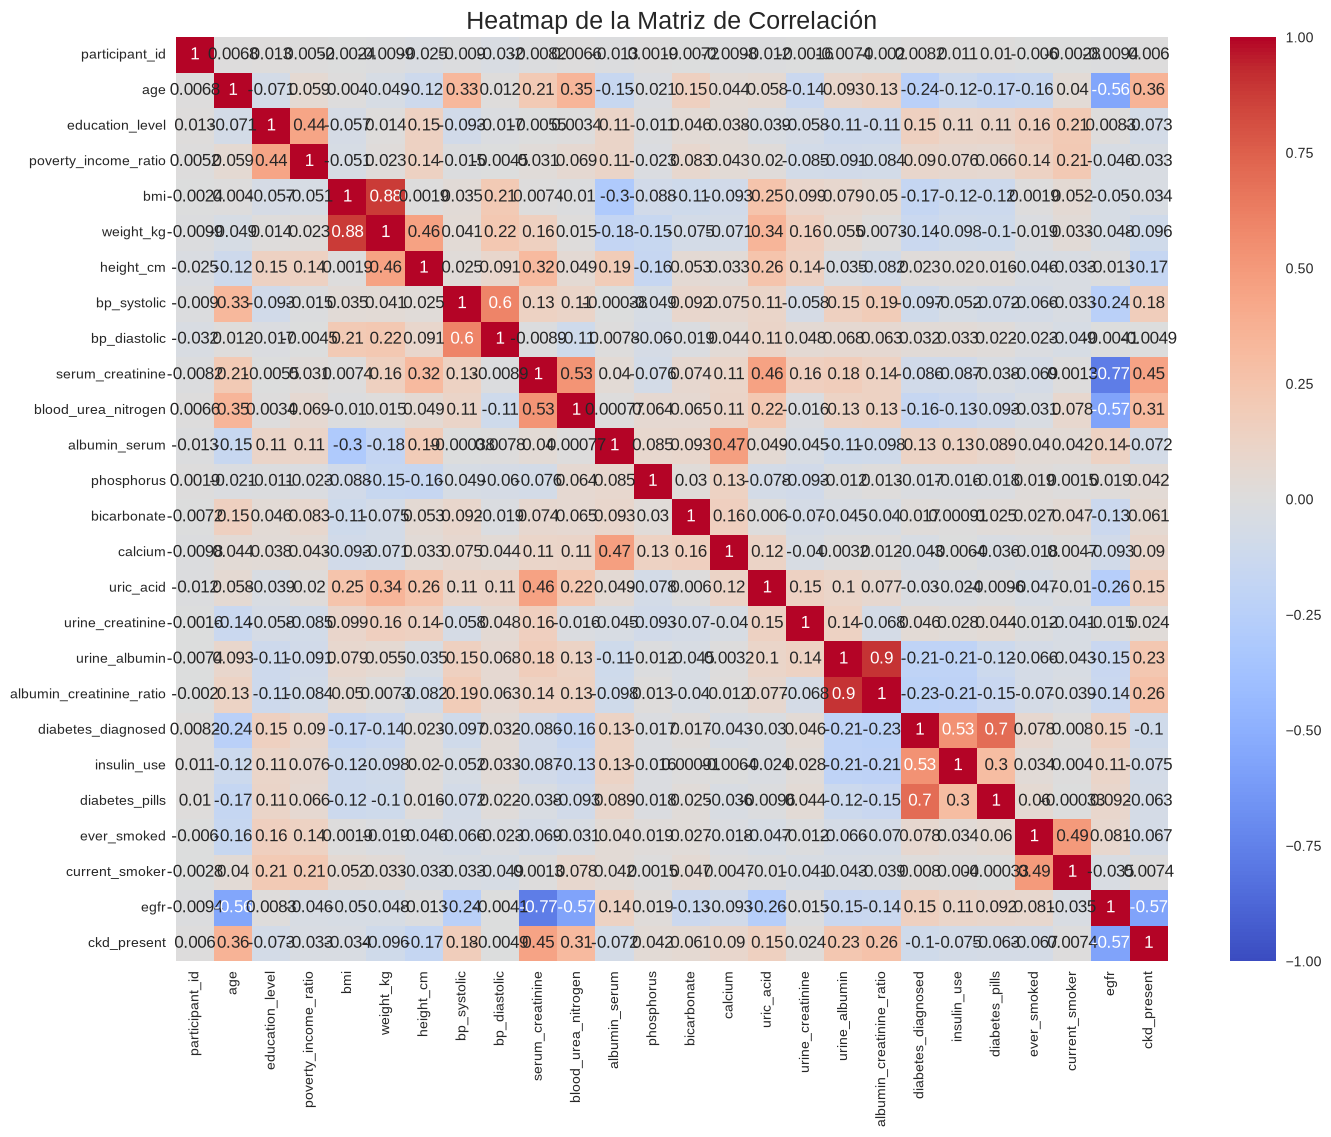

In [10]:


CleanNumeric = Clean.select_dtypes(include=[np.number])
# Generamos la matriz de correlacion, teniendo en cuenta unicamente valores numericos
correlation_matrix = CleanNumeric.corr()

%matplotlib inline
#imprimimos la matriz como un heatmap
plt.figure(figsize=(16,12))
sns.heatmap(correlation_matrix, vmin=-1.0, vmax=1.0, center=0.0, annot=True, cmap='coolwarm')
plt.title('Heatmap de la Matriz de Correlación', fontsize=18)
plt.show()

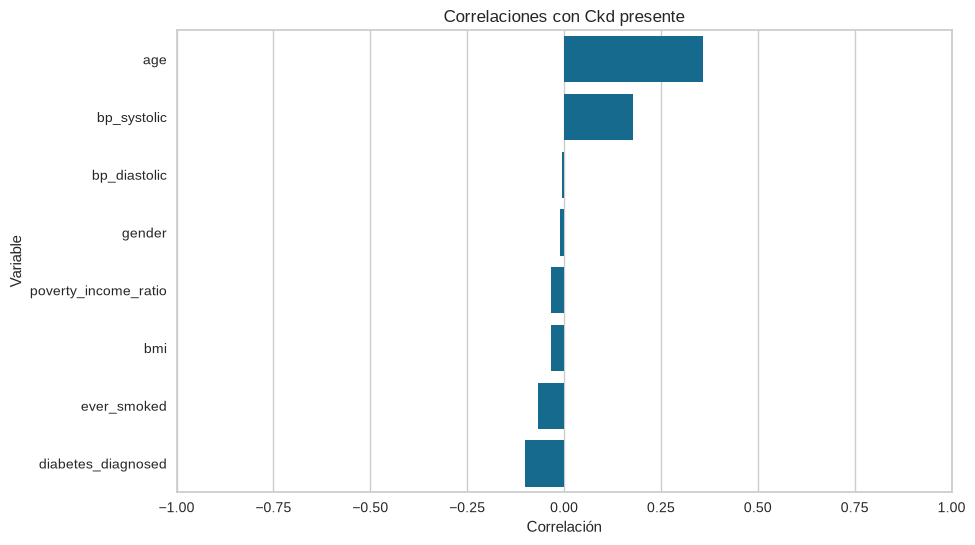

age                     0.359458
bp_systolic             0.177082
bp_diastolic           -0.004912
gender                 -0.011369
poverty_income_ratio   -0.032591
bmi                    -0.033663
ever_smoked            -0.067331
diabetes_diagnosed     -0.100432
Name: ckd_present, dtype: float64


In [11]:

#ANALISIS MULTIVARIADO GONZA HP3. 
#edad, sexo, BMI, presión arterial, diabetes, tabaquismo y nivel socioeconómico . 
Variables = ["age","gender","bmi","bp_systolic","bp_diastolic","diabetes_diagnosed","ever_smoked","poverty_income_ratio","ckd_present"]
X = Clean[Variables]
X['gender'] = Clean['gender'].map({'Male': 0.0, 'Female': 1.0}).astype(float)#Convierto un string a dicotomica float
correlation_matrix = X.corr()
ckd_present_correlations = correlation_matrix['ckd_present'].drop('ckd_present')

# Ordena las correlaciones de mayor a menor
sorted_correlations = ckd_present_correlations.sort_values(ascending=False)

# Crea un gráfico de barras para visualizar las correlaciones
plt.figure(figsize=(10, 6))
plt.grid(True)
sns.barplot(x=sorted_correlations.values, y=sorted_correlations.index)
plt.title('Correlaciones con Ckd presente')
plt.xlabel('Correlación')
plt.ylabel('Variable')
plt.xlim([-1, 1])
plt.show()
print(sorted_correlations)

In [12]:
variable_objetivo = 'ckd_stage_float'
mapped_ckd = Clean.select_dtypes(include=[np.number])
mapped_ckd['ckd_stage_float'] = (Clean['ckd_stage']
    .map({
    "No CKD": -1.0,
    "Stage 1 (Kidney Damage)": 1.0,
    "Stage 2 (Mildly Decreased)": 2.0,
    "Stage 3a (Mild-Moderate)": 3.0,
    "Stage 3b (Moderate-Severe)": 4.0,
    "Stage 4 (Severely Decreased)": 5.0,
    "Stage 5 (Kidney Failure)": 6.0,
    "Unknown": 0.0,
}).astype(float))
# Seleccionamos únicamente la columna de la variable elegida y la ordenamos de mayor a menor

#Clean['ckd_stage'].head()
tabla_correlacion = mapped_ckd.corr()[[variable_objetivo]].sort_values(by=variable_objetivo, ascending=False)
#print(mapped_ckd['age'].value_counts(dropna=False))
display(tabla_correlacion)



,ckd_stage_float
ckd_stage_float,1.000000
ckd_present,0.732157
serum_creatinine,0.658407
blood_urea_nitrogen,0.486233
age,0.452563
bp_systolic,0.231309
uric_acid,0.223213
albumin_creatinine_ratio,0.208898
urine_albumin,0.205487
calcium,0.075722


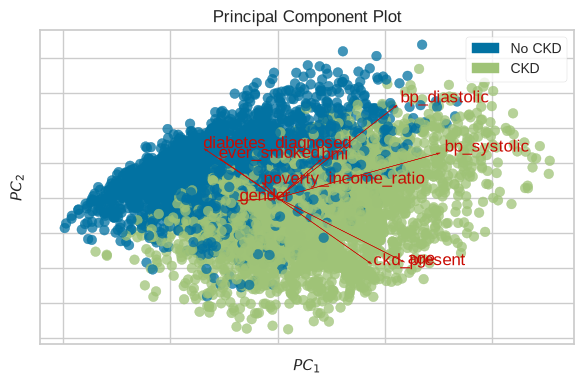

<Axes: title={'center': 'Principal Component Plot'}, xlabel='$PC_1$', ylabel='$PC_2$'>

In [13]:


# 1. Definir un tamaño más chico para la figura (ancho, alto en pulgadas)
plt.figure(figsize=(6, 4))

# 2. Inicializar el visualizador (puedes nombrar las clases de tu variable dicotómica)
viz = PcaViz(
    scale=True,         
    proj_features=True,  
    projection=2,        
    classes=['No CKD', 'CKD']  # Etiquetas opcionales para la leyenda
)

# 3. Pasar X y la variable dicotómica 'y' para colorear los puntos automáticamente
viz.fit_transform(X, Clean['ckd_present'])

# 4. Asegurar el tamaño y mostrar el gráfico
viz.ax.figure.set_size_inches(6, 4)
viz.show()

In [14]:


# Supongamos que X son tus datos ya escalados
# Instanciamos PCA (si no especificas n_components, calcula tantas como dimensiones tenga X)
pca = PCA()
pca.fit(X)

# 1. Varianza explicada por cada dimensión individualmente (en porcentaje)
varianza_individual = pca.explained_variance_ratio_ * 100

# 2. Varianza acumulada desde 1 hasta N dimensiones (en porcentaje)
varianza_acumulada = np.cumsum(pca.explained_variance_ratio_) * 100

# Mostrar el aporte de cada dimensión y el acumulado
for i, (ind, acum) in enumerate(
    zip(varianza_individual, varianza_acumulada), 1
):
  print(
      f"Dimensión {i}: aporta un {ind:.2f}% | Acumulado: {acum:.2f}% de la"
      " información"
  )

Dimensión 1: aporta un 55.96% | Acumulado: 55.96% de la información
Dimensión 2: aporta un 31.47% | Acumulado: 87.43% de la información
Dimensión 3: aporta un 7.48% | Acumulado: 94.92% de la información
Dimensión 4: aporta un 4.63% | Acumulado: 99.55% de la información
Dimensión 5: aporta un 0.34% | Acumulado: 99.88% de la información
Dimensión 6: aporta un 0.04% | Acumulado: 99.92% de la información
Dimensión 7: aporta un 0.03% | Acumulado: 99.95% de la información
Dimensión 8: aporta un 0.03% | Acumulado: 99.98% de la información
Dimensión 9: aporta un 0.02% | Acumulado: 100.00% de la información


In [15]:

# 1. Preparación de datos (Ejemplo con fórmula de R style)
# Asumimos un DataFrame llamado df con las columnas:
# Ckd_present, edad, bmi, presion_arterial, diabetes, tabaquismo, ses (nivel socioeconómico), sexo


modelo_formula = (
    "ckd_present ~ age + bmi + bp_systolic + bp_diastolic + "
    "poverty_income_ratio + C(gender) + C(diabetes_diagnosed) + C(ever_smoked)"
)


# Ajustamos el modelo GLM con familia Binomial (Logit)
modelo = smf.logit(formula=modelo_formula, data=X).fit()

# 2. Ver el resumen estadístico completo (Coeficientes, Error Estándar, z, p-valores, IC)
print(modelo.summary())

# 3. Calcular los Odds Ratios (OR) y sus intervalos de confianza al 95%
params = modelo.params
conf = modelo.conf_int()
conf['OR'] = np.exp(params)
conf.columns = ['IC_2.5%', 'IC_97.5%', 'Odds_Ratio']

print("\n--- ODDS RATIOS Y INTERVALOS DE CONFIANZA ---")
print(conf[['Odds_Ratio', 'IC_2.5%', 'IC_97.5%']])

Optimization terminated successfully.
         Current function value: 0.580923
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:            ckd_present   No. Observations:                 7509
Model:                          Logit   Df Residuals:                     7500
Method:                           MLE   Df Model:                            8
Date:                Tue, 10 Nov 2026   Pseudo R-squ.:                  0.1135
Time:                        22:20:22   Log-Likelihood:                -4362.1
converged:                       True   LL-Null:                       -4920.6
Covariance Type:            nonrobust   LLR p-value:                8.685e-236
                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept                       -1.8439      0.287     -6.415      0.000

In [16]:
or_table = np.exp(modelo.conf_int())
or_table.columns = ['IC_2.5%', 'IC_97.5%']
or_table['Odds_Ratio'] = np.exp(modelo.params)

print(or_table)

                               IC_2.5%  IC_97.5%  Odds_Ratio
Intercept                     0.090067  0.277884    0.158203
C(gender)[T.1.0]              0.915474  1.130262    1.017215
C(diabetes_diagnosed)[T.2.0]  0.785985  1.092541    0.926672
C(ever_smoked)[T.2.0]         0.892689  1.106489    0.993856
age                           1.038470  1.045492    1.041975
bmi                           0.981394  0.998265    0.989793
bp_systolic                   1.016810  1.027499    1.022141
bp_diastolic                  0.969206  0.984202    0.976675
poverty_income_ratio          0.889828  0.952571    0.920665


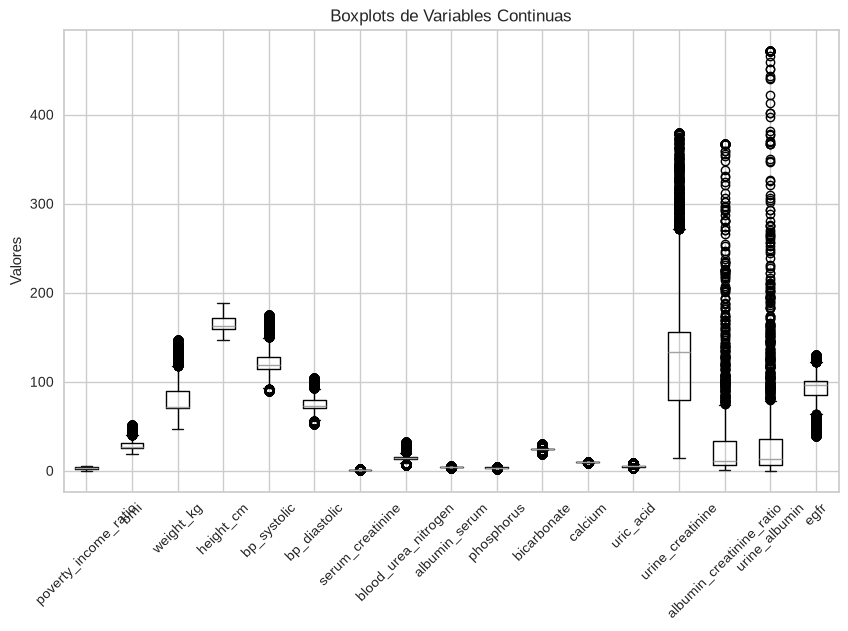

In [17]:

# Generar el boxplot agrupado para las variables seleccionadas
Clean[Cuantitativa_continua].boxplot(figsize=(10, 6), rot=45)

plt.title('Boxplots de Variables Continuas')
plt.ylabel('Valores')
plt.grid(True)
plt.show()

In [18]:

pca = PCA()
pca.fit(X)

# 1. Varianza explicada por cada dimensión individualmente (en porcentaje)
varianza_individual = pca.explained_variance_ratio_ * 100

# 2. Varianza acumulada desde 1 hasta N dimensiones (en porcentaje)
varianza_acumulada = np.cumsum(pca.explained_variance_ratio_) * 100

# Mostrar el aporte de cada dimensión y el acumulado
for i, (ind, acum) in enumerate(
    zip(varianza_individual, varianza_acumulada), 1
):
  print(
      f"Dimensión {i}: aporta un {ind:.2f}% | Acumulado: {acum:.2f}% de la"
      " información"
  )

Dimensión 1: aporta un 55.96% | Acumulado: 55.96% de la información
Dimensión 2: aporta un 31.47% | Acumulado: 87.43% de la información
Dimensión 3: aporta un 7.48% | Acumulado: 94.92% de la información
Dimensión 4: aporta un 4.63% | Acumulado: 99.55% de la información
Dimensión 5: aporta un 0.34% | Acumulado: 99.88% de la información
Dimensión 6: aporta un 0.04% | Acumulado: 99.92% de la información
Dimensión 7: aporta un 0.03% | Acumulado: 99.95% de la información
Dimensión 8: aporta un 0.03% | Acumulado: 99.98% de la información
Dimensión 9: aporta un 0.02% | Acumulado: 100.00% de la información


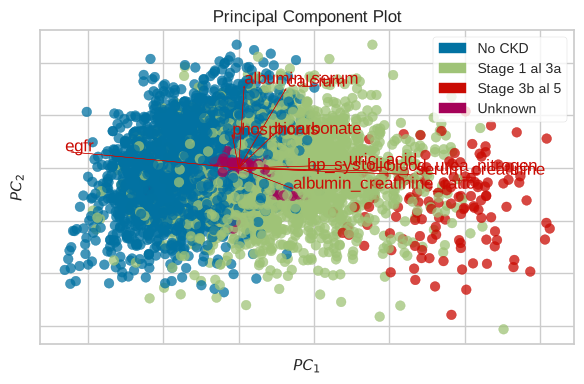

<Axes: title={'center': 'Principal Component Plot'}, xlabel='$PC_1$', ylabel='$PC_2$'>

In [19]:
import matplotlib.pyplot as plt
import pandas as pd
from yellowbrick.features import PCA as PcaViz
features = [
    "bp_systolic",#
    "serum_creatinine",#
    "blood_urea_nitrogen",#
    "albumin_serum",#-
    "phosphorus",#-
    "bicarbonate",#
    "calcium",#-
    "uric_acid",#
    "albumin_creatinine_ratio",
    "egfr"
]

X = Clean[features]

mapping_grupos = { #no se notaba con tantos colores como categorias ya que se perdian las flechas
    "No CKD": "No CKD",
    "Stage 1 (Kidney Damage)": "Stage 1 al 3a",
    "Stage 2 (Mildly Decreased)": "Stage 1 al 3a",
    "Stage 3a (Mild-Moderate)": "Stage 1 al 3a",
    "Stage 3b (Moderate-Severe)": "Stage 3b al 5",
    "Stage 4 (Severely Decreased)": "Stage 3b al 5",
    "Stage 5 (Kidney Failure)": "Stage 3b al 5",
    "Unknown": "Unknown",
}

Clean["ckd_grouped"] = Clean["ckd_stage"].map(mapping_grupos)

y = (
    Clean["ckd_grouped"]
    .map({"No CKD": 0, "Stage 1 al 3a": 1, "Stage 3b al 5": 2, "Unknown": 3})
    .astype(int)
)
classes_names = ["No CKD", "Stage 1 al 3a", "Stage 3b al 5", "Unknown"]
plt.figure(figsize=(6, 4))

viz = PcaViz(
    scale=True,
    proj_features=True,
    projection=2,
    classes=classes_names,
)

viz.fit_transform(X, y)
viz.ax.figure.set_size_inches(6, 4)
viz.show()

serum_creatinine            0.759333
blood_urea_nitrogen         0.533328
uric_acid                   0.272670
phosphorus                  0.079004
calcium                     0.031092
albumin_creatinine_ratio    0.025719
bp_systolic                 0.015116
bicarbonate                -0.022609
albumin_serum              -0.128382
egfr                       -0.850423
Name: ckd_stage_float, dtype: float64

(-1.0, 1.0)

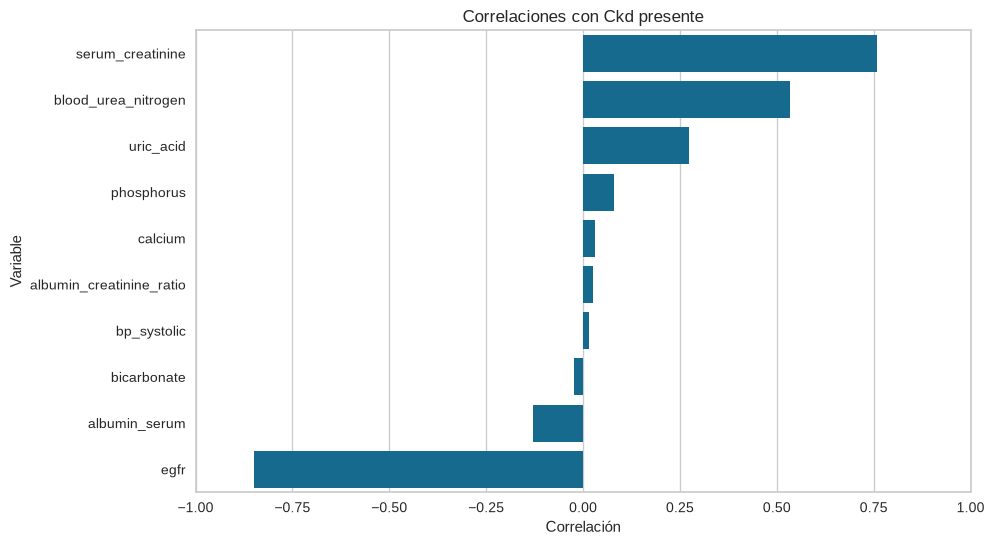

In [20]:
variable_objetivo = 'ckd_stage_float'
mapped_ckd = Clean[features]
ckd_positive = Clean.drop(Clean[Clean['ckd_stage'].isin(['No CKD', 'Unknown'])].index)
mapped_ckd['ckd_stage_float'] = (ckd_positive['ckd_stage']
    .map({
    "Stage 1 (Kidney Damage)": 1.0,
    "Stage 2 (Mildly Decreased)": 2.0,
    "Stage 3a (Mild-Moderate)": 3.0,
    "Stage 3b (Moderate-Severe)": 4.0,
    "Stage 4 (Severely Decreased)": 5.0,
    "Stage 5 (Kidney Failure)": 5.0,#Combino kidney failure con severly decrease por bajos datos
}).astype(float))
mapped_ckd = mapped_ckd.dropna()
# Seleccionamos únicamente la columna de la variable elegida y la ordenamos de mayor a menor

#Clean['ckd_stage'].head()
tabla_correlacion = mapped_ckd.corr()[[variable_objetivo]].sort_values(by=variable_objetivo, ascending=False)


tabla_correlacion = tabla_correlacion['ckd_stage_float'].drop('ckd_stage_float')

#print(mapped_ckd['age'].value_counts(dropna=False))
display(tabla_correlacion)

plt.figure(figsize=(10, 6))
plt.grid(True)
sns.barplot(x=tabla_correlacion.values, y=tabla_correlacion.index)
plt.title('Correlaciones con Ckd presente')
plt.xlabel('Correlación')
plt.ylabel('Variable')
plt.xlim([-1, 1])
#plt.show()

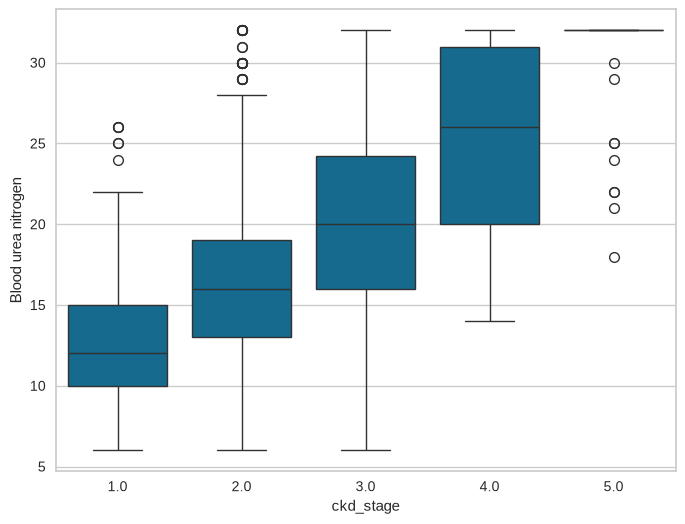

In [21]:
plt.figure(figsize=(8, 6))
# Separamos nuestra variable independiente
X = mapped_ckd['blood_urea_nitrogen']
# y nuestra variable objetivo (variable dependiente)
y = mapped_ckd['ckd_stage_float']

#plt.scatter(mapped_ckd['blood_urea_nitrogen'],mapped_ckd['ckd_stage_float'], alpha=0.5)
#plt.xlabel('Blood urea nitrogen')
#plt.ylabel('ckd_stage')
#plt.show()

sns.boxplot(x=mapped_ckd['ckd_stage_float'], y=mapped_ckd['blood_urea_nitrogen'])
plt.xlabel('ckd_stage')
plt.ylabel('Blood urea nitrogen')
plt.show()

In [22]:


grupos = [g['blood_urea_nitrogen'].values
          for _, g in mapped_ckd.groupby('ckd_stage_float')]

H, p = stats.kruskal(*grupos)
print(f"Kruskal-Wallis: H = {H:.3f}, p = {p:.4g}")


Kruskal-Wallis: H = 537.041, p = 6.51e-115


In [23]:
from statsmodels.miscmodels.ordinal_model import OrderedModel

# Sin constante: OrderedModel estima los umbrales por su cuenta
X = mapped_ckd[['blood_urea_nitrogen']]
y = mapped_ckd['ckd_stage_float'].astype(int)

modelo_ord = OrderedModel(y, X, distr='logit')
res_ord = modelo_ord.fit(method='bfgs', disp=False)
print(res_ord.summary())

# Odds ratio por cada unidad de BUN
print("Odds ratio:", np.exp(res_ord.params['blood_urea_nitrogen']))

                             OrderedModel Results                             
Dep. Variable:        ckd_stage_float   Log-Likelihood:                -1958.9
Model:                   OrderedModel   AIC:                             3928.
Method:            Maximum Likelihood   BIC:                             3957.
Date:                Tue, 10 Nov 2026                                         
Time:                        22:20:24                                         
No. Observations:                2514                                         
Df Residuals:                    2509                                         
Df Model:                           1                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
blood_urea_nitrogen     0.2338      0.009     24.812      0.000       0.215       0.252
1/2                     1

In [24]:
import numpy as np
import statsmodels.api as sm

# Separamos nuestra variable independiente
X = mapped_ckd['blood_urea_nitrogen'] #Cuantitativa continua
# y nuestra variable objetivo (variable dependiente)
y = mapped_ckd['ckd_stage_float'] #Cuantitativa_discreta

# Agregamos una constante como característica, para estimar la ordenada al origen
X = sm.add_constant(X)
# Ajustamos el modelo
model = sm.OLS(y, X).fit()

#print(mapped_ckd['ckd_stage_float'].value_counts(dropna=False))
# Imprimimos el resumen de los resultados
print(model.summary())
#print(y)

                            OLS Regression Results                            
Dep. Variable:        ckd_stage_float   R-squared:                       0.284
Model:                            OLS   Adj. R-squared:                  0.284
Method:                 Least Squares   F-statistic:                     998.5
Date:                Tue, 10 Nov 2026   Prob (F-statistic):          8.15e-185
Time:                        22:20:24   Log-Likelihood:                -2261.3
No. Observations:                2514   AIC:                             4527.
Df Residuals:                    2512   BIC:                             4538.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                   0.9890    

In [25]:
model.resid

9       -0.004011
21       0.131330
26       0.199001
30       1.845589
44      -0.071681
           ...   
11909   -0.139352
11911    0.469683
11917    0.792977
11923    0.657636
11932    0.995989
Length: 2514, dtype: float64

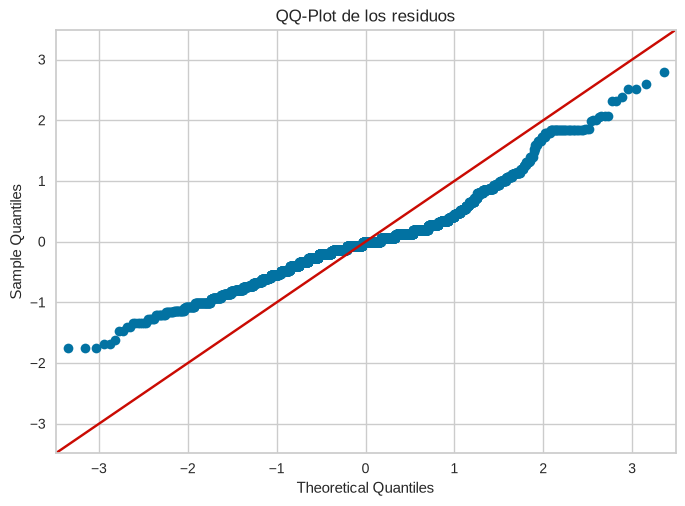

In [26]:
sm.qqplot(model.resid, line='45')
plt.title("QQ-Plot de los residuos")
plt.show()

In [27]:
from scipy.stats import shapiro

# aplicamos Shapiro-Wilk sobre los residuos
_, p = shapiro(model.resid)
print("p = %.4f" % (p))
# comparamos con el alpha
alpha = 0.05
if p > alpha:
    print("Se distribuyen normal (falló en rechazarse la hipótesis nula)")
else:
    print('No se distribuyen normal (se rechazó la hipótesis nula)')

p = 0.0000
No se distribuyen normal (se rechazó la hipótesis nula)


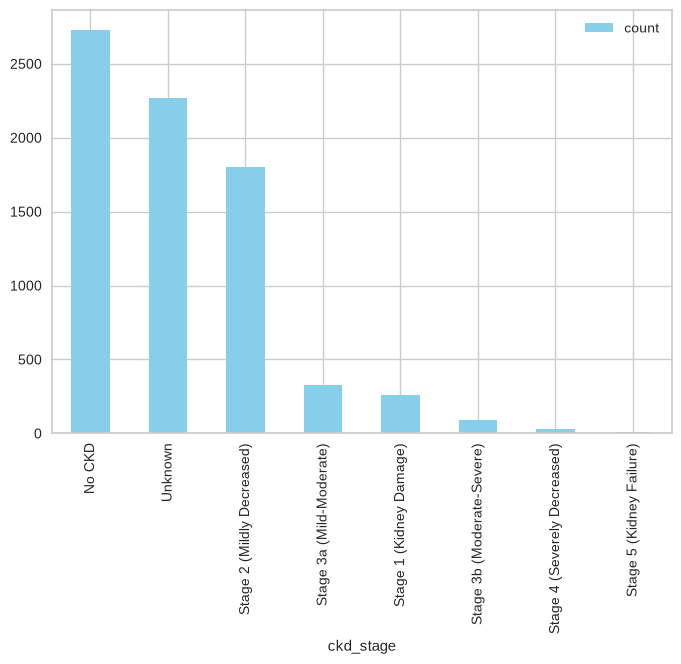

In [28]:


# 2. Usar el nombre de la columna o el índice de las columnas si son numéricos
counts = Clean['ckd_stage'].value_counts().reset_index()
counts.columns = ['ckd_stage', 'count']

counts.plot.bar(x='ckd_stage', y='count', color='skyblue')
plt.show()   

In [29]:


# 1. Asegurar la ejecución del preprocesamiento y limpieza sobre el dataset
# (Asumiendo que 'Clean' ya fue procesado con la celda provista)
df_clean = Clean.copy()

# Si 'unknown' u otras variantes quedaron en ckd_stage o ethnicity, filtrar casos no válidos
df_clean = df_clean[~df_clean['ckd_stage'].astype(str).str.lower().str.startswith('unknown')]

# 2. Filtrar los casos identificados con CKD (ckd_present == 1)
ckd_cases = df_clean[df_clean['ckd_present'] == 1]

# 3. Distribución de frecuencias y proporciones por etnia en los casos identificados
frecuencias_etnia = ckd_cases['ethnicity'].value_counts()
porcentajes_etnia = ckd_cases['ethnicity'].value_counts(normalize=True) * 100

resumen_etnia = pd.DataFrame({
    'Casos': frecuencias_etnia,
    'Porcentaje (%)': porcentajes_etnia.round(2)
})
print("--- Distribución de casos de CKD por Etnia ---")
print(resumen_etnia)

# 4. Tabla de contingencia bivariada (ethnicity vs ckd_present)
tabla_contingencia = pd.crosstab(df_clean['ethnicity'], df_clean['ckd_present'], margins=True)
print("\n--- Tabla de Contingencia (ethnicity vs ckd_present) ---")
print(tabla_contingencia)

# 5. Test de Independencia Chi-cuadrado
obs = pd.crosstab(df_clean['ethnicity'], df_clean['ckd_present'])
chi2_stat, p_val, dof, expected = stats.chi2_contingency(obs)

alpha = 0.05
chi2_critico = stats.chi2.ppf(1 - alpha, dof)

print("\n--- Test Chi-cuadrado de Independencia ---")
print(f"Chi2 Observado: {chi2_stat:.4f}")
print(f"Grados de libertad: {dof}")
print(f"Valor crítico (alpha=0.05): {chi2_critico:.4f}")
print(f"p-valor: {p_val:.4e}")

--- Distribución de casos de CKD por Etnia ---
                    Casos  Porcentaje (%)
ethnicity                                
Non-Hispanic White   1642           65.31
Non-Hispanic Black    347           13.80
Other Hispanic        199            7.92
Other/Multiracial     151            6.01
Mexican American       93            3.70
Non-Hispanic Asian     82            3.26

--- Tabla de Contingencia (ethnicity vs ckd_present) ---
ckd_present            0     1   All
ethnicity                           
Mexican American     256    93   349
Non-Hispanic Asian   192    82   274
Non-Hispanic Black   257   347   604
Non-Hispanic White  1519  1642  3161
Other Hispanic       334   199   533
Other/Multiracial    170   151   321
All                 2728  2514  5242

--- Test Chi-cuadrado de Independencia ---
Chi2 Observado: 165.3433
Grados de libertad: 5
Valor crítico (alpha=0.05): 11.0705
p-valor: 7.1847e-34


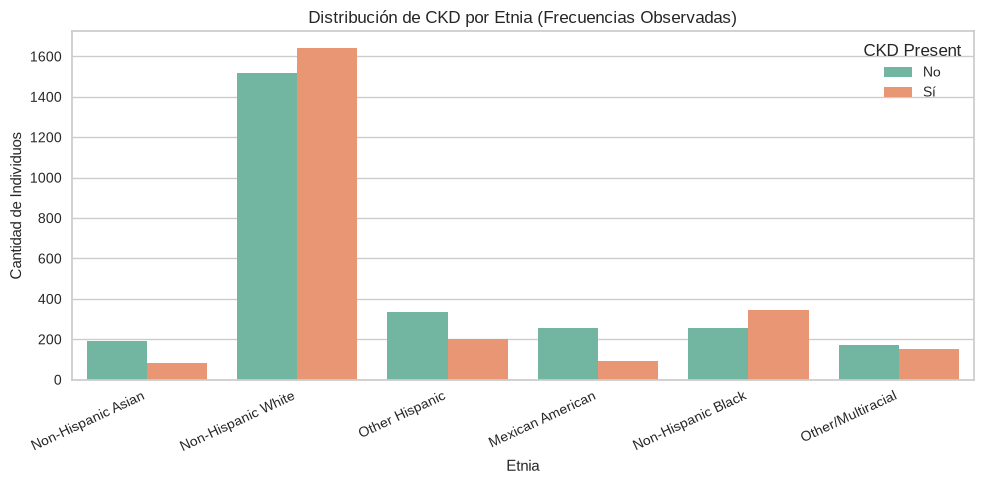

In [30]:


# df_clean proviene de la celda de limpieza
plt.figure(figsize=(10, 5))
sns.countplot(data=df_clean, x='ethnicity', hue='ckd_present', palette='Set2')
plt.title('Distribución de CKD por Etnia (Frecuencias Observadas)')
plt.xlabel('Etnia')
plt.ylabel('Cantidad de Individuos')
plt.xticks(rotation=25, ha='right')
plt.legend(title='CKD Present', labels=['No', 'Sí'])
plt.tight_layout()
plt.show()

In [31]:
# 1. Asegurar la muestra limpia y válida
df_clean = Clean.copy()
df_clean = df_clean[~df_clean['ckd_stage'].astype(str).str.lower().str.startswith('unknown')]

# Separar los dos grupos por presencia/ausencia de daño renal
grupo_sano = df_clean[df_clean['ckd_present'] == 0]
grupo_ckd = df_clean[df_clean['ckd_present'] == 1]

variables_pa = ['bp_systolic', 'bp_diastolic']

print("=== 1. ESTADÍSTICAS DESCRIPTIVAS POR GRUPO ===")
for var in variables_pa:
    resumen = df_clean.groupby('ckd_present')[var].agg(['count', 'mean', 'median', 'std', 'min', 'max'])
    print(f"\nEstadísticos para {var}:")
    print(resumen.round(2))

# 2. VALIDACIÓN DE SUPUESTOS
print("\n=== 2. COMPROBACIÓN DE SUPUESTOS ===")
for var in variables_pa:
    print(f"\n--- Variable: {var} ---")
    
    # a) Normalidad: Kolmogorov-Smirnov / Anderson-Darling (n > 50)
    # Estandarizamos para contrastar contra la distribución normal teórica N(0,1)
    sano_std = (grupo_sano[var] - grupo_sano[var].mean()) / grupo_sano[var].std()
    ckd_std = (grupo_ckd[var] - grupo_ckd[var].mean()) / grupo_ckd[var].std()
    
    ks_sano = stats.kstest(sano_std, 'norm')
    ks_ckd = stats.kstest(ckd_std, 'norm')
    
    print(f"K-S Grupo Sano (No CKD): stat={ks_sano.statistic:.4f}, p-valor={ks_sano.pvalue:.4e}")
    print(f"K-S Grupo CKD: stat={ks_ckd.statistic:.4f}, p-valor={ks_ckd.pvalue:.4e}")
    
    # b) Homocedasticidad: Test de Levene
    levene_res = stats.levene(grupo_sano[var], grupo_ckd[var], center='median')
    print(f"Test de Levene (Homocedasticidad): stat={levene_res.statistic:.4f}, p-valor={levene_res.pvalue:.4e}")

# 3. CONTRASTES DE HIPÓTESIS BIVARIADOS
print("\n=== 3. PRUEBAS ESTADÍSTICAS BIVARIADAS ===")
for var in variables_pa:
    print(f"\n--- Resultados para {var} ---")
    
    # Test t con corrección de Welch (no asume varianzas iguales)
    t_stat, p_t = stats.ttest_ind(grupo_ckd[var], grupo_sano[var], equal_var=False, alternative='greater')
    print(f"Test t de Welch (una cola: CKD > No CKD): t={t_stat:.4f}, p-valor={p_t:.4e}")
    
    # Alternativa No Paramétrica: U de Mann-Whitney
    u_stat, p_u = stats.mannwhitneyu(grupo_ckd[var], grupo_sano[var], alternative='greater')
    print(f"Mann-Whitney U (una cola: CKD > No CKD): U={u_stat:.1f}, p-valor={p_u:.4e}")

=== 1. ESTADÍSTICAS DESCRIPTIVAS POR GRUPO ===

Estadísticos para bp_systolic:
             count    mean  median    std   min    max
ckd_present                                           
0             2728  118.33   117.0  14.75  90.0  175.0
1             2514  126.92   124.0  18.53  90.0  175.0

Estadísticos para bp_diastolic:
             count   mean  median    std   min    max
ckd_present                                          
0             2728  74.69    74.0   9.91  53.0  104.0
1             2514  75.56    75.0  11.30  53.0  104.0

=== 2. COMPROBACIÓN DE SUPUESTOS ===

--- Variable: bp_systolic ---
K-S Grupo Sano (No CKD): stat=0.0752, p-valor=7.4911e-14
K-S Grupo CKD: stat=0.0708, p-valor=2.0994e-11
Test de Levene (Homocedasticidad): stat=116.2359, p-valor=8.0526e-27

--- Variable: bp_diastolic ---
K-S Grupo Sano (No CKD): stat=0.0661, p-valor=8.2766e-11
K-S Grupo CKD: stat=0.0552, p-valor=4.2274e-07
Test de Levene (Homocedasticidad): stat=39.9199, p-valor=2.8645e-10

=== 3

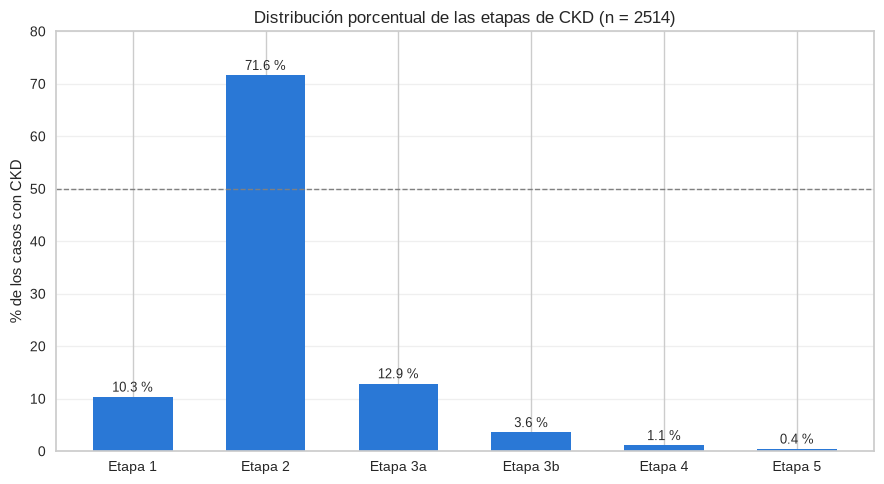

In [32]:


orden = ["Stage 1 (Kidney Damage)", 
         "Stage 2 (Mildly Decreased)", 
         "Stage 3a (Mild-Moderate)",
         "Stage 3b (Moderate-Severe)", }
         "Stage 4 (Severely Decreased)", 
         "Stage 5 (Kidney Failure)"]
etiq = ["Etapa 1", "Etapa 2", "Etapa 3a", "Etapa 3b", "Etapa 4", "Etapa 5"]

c = Clean[Clean.ckd_stage.isin(orden)]                 # excluye No CKD y Unknown
conteo = c.ckd_stage.value_counts().reindex(orden)
pct = conteo / conteo.sum() * 100

fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.bar(etiq, pct, color="#2a78d6", width=0.6)
for r, v in zip(barras, pct):
    ax.text(r.get_x() + r.get_width() / 2, v + 1, f"{v:.1f} %", ha="center", fontsize=9)

ax.axhline(50, color="gray", ls="--", lw=1)            # línea de la mayoría
ax.set_ylim(0, 80)
ax.set_ylabel("% de los casos con CKD")
ax.grid(axis="y", alpha=0.3)
ax.set_title(f"Distribución porcentual de las etapas de CKD (n = {conteo.sum()})")
plt.tight_layout()
plt.show()

In [33]:


var1, var2 = "poverty_income_ratio", "ckd_present"
d = Clean.dropna(subset=[var1, var2])

con = d.loc[d[var2] == 1, var1]
sin = d.loc[d[var2] == 0, var1]

u, p = stats.mannwhitneyu(con, sin, alternative="two-sided")
print(f"n con CKD = {len(con)}, n sin CKD = {len(sin)}")
print(f"Mediana con CKD = {con.median():.2f}, sin CKD = {sin.median():.2f}")
print(f"U = {u:.0f}, p = {p:.2e}")

n con CKD = 4781, n sin CKD = 2728
Mediana con CKD = 2.71, sin CKD = 2.71
U = 6288784, p = 9.55e-03


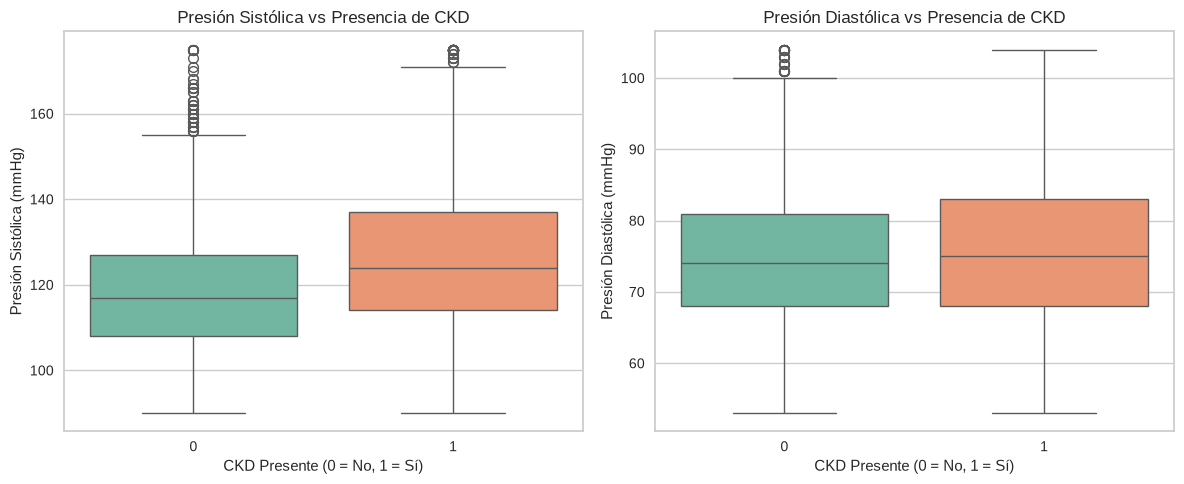

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Boxplot para Sistólica (sin warning)
sns.boxplot(
    ax=axes[0], 

    data=df_clean, 
    x='ckd_present', 
    y='bp_systolic', 
    hue='ckd_present', 
    palette='Set2', 
    legend=False
)
axes[0].set_title('Presión Sistólica vs Presencia de CKD')
axes[0].set_xlabel('CKD Presente (0 = No, 1 = Sí)')
axes[0].set_ylabel('Presión Sistólica (mmHg)')

# Boxplot para Diastólica (sin warning)
sns.boxplot(
    ax=axes[1], 
    data=df_clean, 
    x='ckd_present', 
    y='bp_diastolic', 
    hue='ckd_present', 
    palette='Set2', 
    legend=False
)
axes[1].set_title('Presión Diastólica vs Presencia de CKD')
axes[1].set_xlabel('CKD Presente (0 = No, 1 = Sí)')
axes[1].set_ylabel('Presión Diastólica (mmHg)')

plt.tight_layout()
plt.show()